# Analyse exploratoire — simulations `quentin_house`

**Objectif.** Avant toute modélisation, nous cherchons à comprendre ce que contiennent les 1 000 000 de simulations et, surtout, **où se trouve l'information sur le bâtiment dans les signaux $T_{int}(t)$ et $U(t)$**. Chaque section part d'une question précise, en donne une lecture physique et se termine par la conséquence que nous en tirons pour la modélisation.

**Rappel du problème [Assessment].** À partir de $T_{int}(t)$ et de la sollicitation $U(t)$, prédire :

| Famille | Cibles | Unité |
|---|---|---|
| HLC | coefficient de déperdition global | W/K |
| Hb | $HLC_{ext}$, $HLC_{mit}$ avec $HLC = HLC_{ext} + HLC_{mit}$ | W/K |
| CDT | $\tau_b$, $\tau_n$, $\tau_\infty$ | h |

Le **HLC** est la puissance qu'il faut fournir en continu pour maintenir l'intérieur 1 K au-dessus de l'environnement. Une **constante de temps** $\tau$ mesure la vitesse à laquelle le bâtiment revient à l'équilibre après une perturbation ; pour un système simple, $\tau = C / H$ (capacité thermique divisée par conductance).

**L'intuition physique qui guide l'analyse.** Le bâtiment se représente comme un réseau de résistances et de capacités thermiques. La puissance $U$ chauffe le **nœud d'air**, de faible capacité, qui réagit en quelques minutes. L'air échange avec les **parois**, de forte capacité, dont la dynamique s'étend sur des dizaines d'heures. Les parois perdent enfin de la chaleur vers l'extérieur ($HLC_{ext}$) et vers les espaces mitoyens ($HLC_{mit}$). Nous attendons donc dans $T$ un saut immédiat à chaque allumage, qui reflète la capacité de l'air, puis une montée de plus en plus lente dont l'allure dépend des déperditions et de l'inertie. La difficulté anticipée est que la fenêtre observée est courte devant l'inertie du bâtiment, alors que le HLC est une grandeur d'équilibre. L'EDA confronte ces attentes aux données.

**Fil conducteur.**
1. Les données sont-elles exploitables telles quelles ?
2. Que représente $U$, quel est le pas de temps, et comment les excitations sont-elles générées ?
3. Comment $T$ répond-elle à $U$ ?
4. Que valent les cibles, et quelles relations physiques les lient ?
5. Quelle information $T$ contient-elle réellement sur chaque cible ?
6. Le découpage entraînement/test peut-il faire fuir de l'information ?
7. Synthèse : constats, hypothèses, décisions pour la modélisation.

**En bref.** Les séries couvrent 8 h au pas d'une minute. $U$ est un signal marche/arrêt de 0 ou 7000 W, issu d'une séquence aléatoire commune à toutes les simulations. La contrainte de somme est exacte. Les constantes de temps suivent $\tau \approx C/HLC$ et dépassent presque toujours la fenêtre observée : le régime permanent n'est jamais atteint. À excitation fixée, $T$ est nettement liée au HLC mais faiblement aux constantes de temps longues. Chaque simulation est un bâtiment distinct ; seules les excitations se répètent.

**Conventions.** Chaque affirmation est étiquetée selon sa source :
- **[Assessment]** la spécification ;
- **[Article]** l'article de recherche de coEnergy sur l'identification du HLC par essai court, cité comme contexte physique ;
- **[Mesuré]** ce qui est calculé ici sur les données ;
- **[Hypothèse]** ce qui n'est pas vérifiable, repris dans le tableau final.

**Méthode de calcul.** Le jeu complet (3,9 Go) n'est jamais chargé d'un bloc. La fonction `coenergy.eda.run_eda_pass` parcourt les 20 batchs **un par un, dans l'ordre numérique** (≈ 200 Mo en mémoire), calcule pour chaque simulation des descripteurs et des sommes exactes par pas de temps, puis écrit le tout dans `outputs/eda/`. Ce notebook relit ce cache (la passe complète, ≈ 90 s, est relancée automatiquement s'il est absent). **Toutes les statistiques portent sur le million de simulations** ; seules les figures de courbes individuelles montrent une sélection, justifiée à chaque fois.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coenergy import analysis as an
from coenergy.eda import TARGET_LABELS, ensure_eda_results
from coenergy.plots import (BLUES, SERIES, apply_style, plot_band, plot_curves_by_value,
                            plot_series_pairs)

apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

r = ensure_eda_results()
d = r.per_sim
assert (d["global_idx"].to_numpy() == np.arange(len(d))).all()
print(f"{len(d):,} simulations, {d['batch'].nunique()} batchs, {d.shape[1]} descripteurs par simulation")

1,000,000 simulations, 20 batchs, 32 descripteurs par simulation


## 1. Inventaire et qualité des données

**Question.** Les 20 batchs ont-ils la même structure, et les données sont-elles exploitables telles quelles (valeurs manquantes, valeurs aberrantes, labels) ? Le jeu n'étant jamais chargé en entier, une incohérence entre batchs fausserait toutes les statistiques agrégées.

In [2]:
an.inventory_table(r.meta)

,champ,forme (par batch),dtype,identique dans les 20 batchs
0,HLC,"(50000,)",torch.float32,True
1,Hb,"(50000, 2)",torch.float32,True
2,CDT,"(50000, 3)",torch.float32,True
3,indoor_temperature,"(50000, 480)",torch.float32,True
4,indoor_U,"(50000, 480)",torch.float32,True
5,solicitation,"(50000, 12)",torch.float32,True


In [3]:
an.solicitation_table(r.meta)

,champ,min,max,constant sur 1M
0,max_power_wat,"7,000","7,000",True
1,start_amplitude_wat,0,0,True
2,end_amplitude_wat,0,0,True
3,start_period_hours,0,0,True
4,end_period_hours,0,0,True
5,transition_speed,14,14,True
6,phase_shift,0,0,True
7,average_fluctuation_wat,0,0,True
8,prbs_min_duration_hours,3.895e-06,2,False
9,prbs_max_duration_hours,7.789e-06,4,False


In [4]:
an.quality_summary(r.meta, d).to_frame("valeur")

,valeur
valeurs NaN (T et U),0
valeurs infinies (T et U),0
valeurs distinctes de U,"[0.0, 7000.0]"
"valeurs de U hors {0, max_power}",0
T(0) distinctes,[24.624001]
T min (°C),24.22
T max (°C),51.55
labels Hb identiques,True
labels Hb,"[HLC_mit, HLC_ext]"


**Lecture [Mesuré].**
- Les six tenseurs ont la même forme et le même type (`float32`) dans les 20 batchs : 50 000 simulations × **480 pas** pour les deux séries.
- **Aucune valeur manquante ni infinie.**
- **8 des 12 champs de `solicitation` sont constants sur le million.** Tous les paramètres de l'excitation sinusoïdale (amplitudes, périodes, déphasage) valent 0, `transition_speed` vaut 14, `prbs_seed` vaut 42, `max_power_wat` vaut 7000. Seuls varient les trois paramètres du PRBS : $t_{min}$, $t_{max}$ et $p_{on}$. **Le jeu ne contient donc que des excitations PRBS** (signal marche/arrêt pseudo-aléatoire, défini dans l'annexe de l'article).
- `average_fluctuation_wat` ne figure pas dans l'annexe de l'article et vaut 0 partout : son rôle ne peut pas être établi ici **[Hypothèse H7]**.
- $U$ ne prend que **deux valeurs, 0 et 7000**, et toutes les simulations partent de la **même température** $T(0) = 24{,}624$ °C.
- L'ordre des labels Hb dans les fichiers est `['HLC_mit', 'HLC_ext']`, l'inverse de l'ordre de l'énoncé.

**Conséquences.** Aucun nettoyage n'est nécessaire. Nous lisons l'ordre des labels Hb depuis le fichier plutôt que de le supposer. Le point de départ commun de $T$ ne porte aucune information sur le bâtiment.

## 2. L'excitation $U(t)$

### 2.1 Unité et nature

**Question.** Que représente `indoor_U` ? L'énoncé parle de « sollicitation thermique appliquée » sans en préciser l'unité **[Assessment]**. Dans l'article, l'excitation est une puissance de chauffage $P_{int}$ (W), brute ou nette des pertes par infiltration **[Article]**. La nature de $U$ conditionne la lecture physique de toute la suite.

In [5]:
active = ~d["all_off"]
pd.Series({
    "simulations avec au moins un pas allumé": int(active.sum()),
    "dont max(U) = max_power_wat (7000)": float((d.loc[active, "u_max"] == 7000).mean()),
    "valeurs de U hors {0, 7000}": int(d["n_off_grid"].sum()),
}).to_frame("valeur")

,valeur
simulations avec au moins un pas allumé,9.158e+05
dont max(U) = max_power_wat (7000),1
"valeurs de U hors {0, 7000}",0


**Lecture.**
- **[Mesuré]** Dans toutes les simulations allumées au moins une fois, le maximum de $U$ vaut exactement `max_power_wat`. $U$ est donc une puissance en **watts**, et elle suit la forme d'un PRBS de l'annexe de l'article, où chaque bloc vaut $P_{max}$ ou 0.
- **[Mesuré]** Le signal est strictement binaire. Une puissance « nette » au sens de l'article (puissance électrique moins les pertes par infiltration) ne le serait pas.
- **[Hypothèse H2]** $U$ est la puissance brute injectée dans le nœud d'air de la zone étudiée. La réponse instantanée de $T$ observée en 3.3 va dans ce sens.

### 2.2 Le pas de temps

**Question.** Quel est le pas de temps ? Il n'est stocké nulle part, alors qu'il fixe la durée physique observée. Nous le déduisons de $U$ : les durées des blocs PRBS sont connues en heures ($t_{min}$, avec $t_{max} = 2\,t_{min}$ exactement) et observables en nombre de pas.

**Intuition.** Une « série » est une suite de pas consécutifs dans le même état. Une série intérieure, délimitée par deux commutations, contient au moins un bloc entier, donc dure au moins $t_{min}$. Prenons une simulation avec $t_{min}$ = 1 h = 60 minutes : sa série intérieure la plus courte correspond à un créneau de presque 60 minutes.
- Si un pas dure 1 minute, cette série fait environ 60 pas. Rapport : 60 pas / 60 minutes ≈ 1.
- Si un pas dure 3 minutes, elle ne fait que 20 pas. Rapport : 20 / 60 ≈ 1/3.

Nous calculons ce rapport (plus courte série intérieure en pas, divisée par $t_{min}$ en minutes) pour toutes les simulations qui ont au moins une série intérieure.

In [6]:
an.time_step_table(d)

,t_min >,simulations,rapport min,"quantile 0,1 %",médiane
0,0.1 h,564833,0.8571,0.879,3.798
1,0.25 h,489391,0.9484,0.9596,4.144
2,0.5 h,369047,0.9762,0.9784,4.184
3,1.0 h,141690,1.025,1.026,4.196


**Lecture du tableau [Mesuré].** Chaque ligne restreint l'analyse aux simulations dont $t_{min}$ dépasse le seuil indiqué.
- **Rapport min.** C'est la quantité qui teste l'hypothèse. Dans toutes les simulations, la plus courte série intérieure n'a **jamais plus d'un pas de moins** que $t_{min}$ exprimé en minutes. Ce pas manquant vient de l'arrondi des limites de bloc sur la grille d'une minute. Par exemple, un bloc de 7 minutes peut n'occuper que 6 pas, d'où le rapport 6/7 = 0,857 de la première ligne.
- **Effet du seuil.** Plus $t_{min}$ est grand, moins ce pas manquant pèse, et le rapport minimal tend vers 1 : 0,857, puis 0,948, puis 0,976, puis 1,025.
- **Pas de 3 minutes.** Il donnerait un rapport minimal proche de 0,33, ce que le tableau exclut.
- **Médiane (≈ 4).** Elle ne renseigne pas sur le pas. Une série regroupe généralement plusieurs blocs successifs dans le même état, chacun durant entre $t_{min}$ et $2\,t_{min}$. Seul le minimum est contraint par le pas.

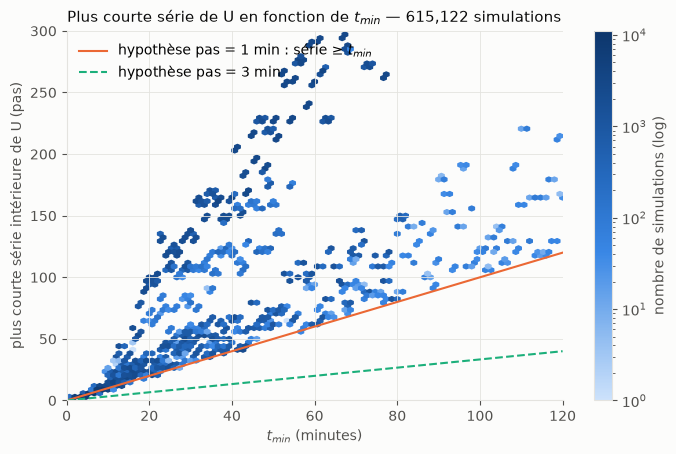

In [7]:
h = d[d["min_run"] > 0]
fig, ax = plt.subplots(figsize=(8, 4.8))
hb = ax.hexbin(h["prbs_min_duration_hours"] * 60, h["min_run"], gridsize=90, bins="log",
               cmap=BLUES, mincnt=1, extent=(0, 120, 0, 300))
x = np.linspace(0, 120, 2)
ax.plot(x, x, color=SERIES[1], label="hypothèse pas = 1 min : série ≥ $t_{min}$")
ax.plot(x, x / 3, color=SERIES[2], linestyle="--", label="hypothèse pas = 3 min")
ax.set_xlim(0, 120); ax.set_ylim(0, 300)
ax.set_xlabel("$t_{min}$ (minutes)")
ax.set_ylabel("plus courte série intérieure de U (pas)")
ax.set_title(f"Plus courte série de U en fonction de $t_{{min}}$ — {len(h):,} simulations")
plt.colorbar(hb, ax=ax, label="nombre de simulations (log)")
ax.legend(loc="upper left")
plt.show()

**Lecture de la figure [Mesuré].**
- La droite « 1 pas = 1 min » est la **borne inférieure** du nuage : les simulations se placent au-dessus et viennent la toucher, à un pas près.
- Le nuage reste loin au-dessus de la droite pointillée qu'impliquerait un pas de 3 minutes.
- Pour $t_{min}$ inférieur à une minute, les blocs sont plus courts qu'un pas, et $U$ peut changer d'état à chaque pas.

**Conclusion [Hypothèse H1, fortement étayée].** **1 pas = 1 minute** : une simulation couvre donc **8 heures**. C'est cohérent avec le contexte de l'article, où les simulations sont intégrées au pas d'une minute et les mesures sur site enregistrées à la minute **[Article]**.

**Conséquence.** Les axes de temps sont exprimés en heures dans la suite. Toutes les dynamiques plus lentes que 8 h ne sont vues que partiellement (section 4.4).

In [8]:
DT_MIN = 1.0
WINDOW_H = 480 * DT_MIN / 60
hours = np.arange(480) * DT_MIN / 60

### 2.3 Une séquence aléatoire commune à toutes les simulations

**Question.** Toutes les simulations ont `prbs_seed = 42`. Leurs excitations sont-elles indépendantes, ou générées à partir des mêmes tirages aléatoires ? L'assessment indique que « chaque simulation représente un scénario unique de sollicitation thermique » **[Assessment]**. Si les signaux $U$ se répètent malgré tout, un découpage aléatoire placera les mêmes excitations en entraînement et en test.

**Intuition.** Si chaque simulation réutilise la même suite de tirages uniformes $u_1, u_2, \dots$, le premier bloc est « allumé » si et seulement si $p_{on} > u_1$. Nous devons alors observer une **frontière nette** en $p_{on}$ entre les simulations qui démarrent allumées et les autres, et non une proportion qui augmente progressivement avec $p_{on}$.

In [9]:
an.shared_draws_evidence(d).to_frame("valeur")

,valeur
p_on min des simulations démarrant allumées,0.8823
p_on max des simulations démarrant éteintes,0.8823
U ≡ 0 : p_on max,0.3829
U ≡ 0 : t_min min (h),0.4334
signaux U distincts,"2,798"
simulations dont le signal U existe dans les 20 batchs,0.9535
effectif médian par signal,53
effectif du signal le plus fréquent,8.416e+04


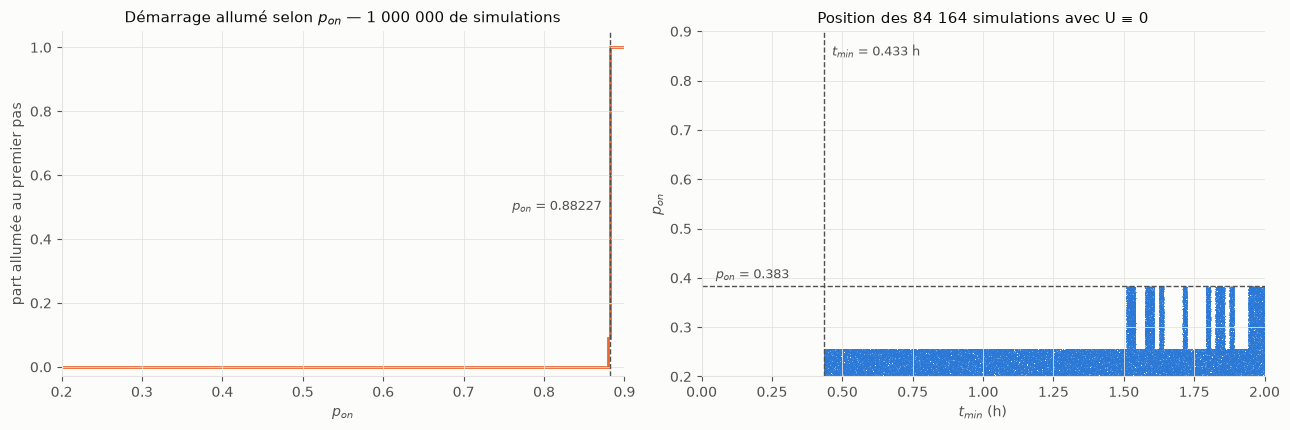

In [10]:
starts_on = d["first_on"] == 0
threshold = float(d.loc[starts_on, "prbs_probability_on"].min())
off = d[d["all_off"]]
pb = np.linspace(0.2, 0.9, 281)
n_all, _ = np.histogram(d["prbs_probability_on"], bins=pb)
n_on, _ = np.histogram(d.loc[starts_on, "prbs_probability_on"], bins=pb)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].stairs(n_on / n_all, pb, color=SERIES[1], linewidth=2, baseline=None)
axes[0].axvline(threshold, color="#52514e", linewidth=1, linestyle="--")
axes[0].text(threshold - 0.01, 0.5, f"$p_{{on}}$ = {threshold:.5f}", color="#52514e",
             fontsize=9, ha="right", va="center")
axes[0].set_xlim(0.2, 0.9); axes[0].set_ylim(-0.03, 1.05)
axes[0].set_xlabel("$p_{on}$"); axes[0].set_ylabel("part allumée au premier pas")
axes[0].set_title("Démarrage allumé selon $p_{on}$ — 1 000 000 de simulations")
p_max, t_low = off["prbs_probability_on"].max(), off["prbs_min_duration_hours"].min()
axes[1].scatter(off["prbs_min_duration_hours"], off["prbs_probability_on"], s=0.4, color=SERIES[0],
                alpha=0.6, linewidths=0, rasterized=True)
axes[1].axhline(p_max, color="#52514e", linewidth=1, linestyle="--")
axes[1].axvline(t_low, color="#52514e", linewidth=1, linestyle="--")
axes[1].text(0.05, p_max + 0.015, f"$p_{{on}}$ = {p_max:.3f}", color="#52514e", fontsize=9)
axes[1].text(t_low + 0.03, 0.85, f"$t_{{min}}$ = {t_low:.3f} h", color="#52514e", fontsize=9)
axes[1].set_xlim(0, 2); axes[1].set_ylim(0.2, 0.9)
axes[1].set_xlabel("$t_{min}$ (h)"); axes[1].set_ylabel("$p_{on}$")
axes[1].set_title(f"Position des {len(off):,} simulations avec U ≡ 0".replace(",", " "))
fig.tight_layout(); plt.show()

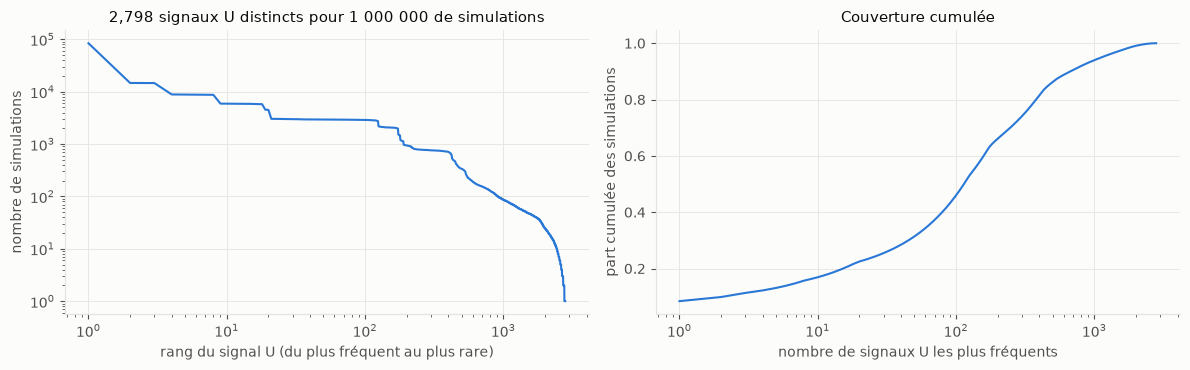

In [11]:
counts = d["u_hash"].value_counts().to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].loglog(np.arange(1, counts.size + 1), counts, color=SERIES[0])
axes[0].set_xlabel("rang du signal U (du plus fréquent au plus rare)")
axes[0].set_ylabel("nombre de simulations")
axes[0].set_title(f"{counts.size:,} signaux U distincts pour 1 000 000 de simulations")
axes[1].semilogx(np.arange(1, counts.size + 1), np.cumsum(counts) / counts.sum(), color=SERIES[0])
axes[1].set_xlabel("nombre de signaux U les plus fréquents")
axes[1].set_ylabel("part cumulée des simulations")
axes[1].set_title("Couverture cumulée")
fig.tight_layout(); plt.show()

**Lecture [Mesuré].**
- **La frontière est nette** (figure de gauche). Une simulation démarre allumée si et seulement si $p_{on} > 0{,}88227$ ; les deux groupes ne se chevauchent pas.
- **$U \equiv 0$ ne survient que dans une région en escalier, bien délimitée** (figure de droite), contenue dans $p_{on} < 0{,}383$ et $t_{min} > 0{,}433$ h. Interprétation : avec des blocs longs, 8 h ne contiennent que quelques blocs, et les premiers tirages de la séquence commune sont tous supérieurs à 0,383 ; aucun bloc ne s'allume si $p_{on}$ est plus petit.
- **Le signal $U$ est donc une fonction déterministe de $(t_{min}, p_{on})$, constante par morceaux** **[Hypothèse H6]**. Les paramètres sont bien uniques, conformément à l'assessment : 1 000 000 de couples $(t_{min}, p_{on})$ distincts. Mais ils ne produisent que **2 798 signaux distincts**, car deux couples voisins donnent souvent exactement le même signal.
- Le signal le plus fréquent est $U \equiv 0$ (84 164 simulations). L'effectif médian d'un signal est 53, et **95 % des simulations ont un signal présent dans les 20 batchs**.

**Conséquences.**
- Un découpage aléatoire par simulation place **les mêmes excitations** en entraînement et en test. Ce n'est pas une fuite sur les cibles, puisque l'excitation est indépendante du bâtiment (section 5.3). Mais un tel découpage ne mesure pas la généralisation à une excitation nouvelle : **nous complétons donc l'évaluation par un test groupé par signal $U$**.
- Pour l'analyse, des groupes de milliers de bâtiments soumis à **exactement la même excitation** permettent d'isoler l'effet du bâtiment (section 5).

### 2.4 Énergie injectée et richesse de l'excitation

**Question.** Toutes les simulations apportent-elles la même quantité d'information ? Une excitation pauvre (peu d'énergie, peu de commutations) sollicite peu le bâtiment.

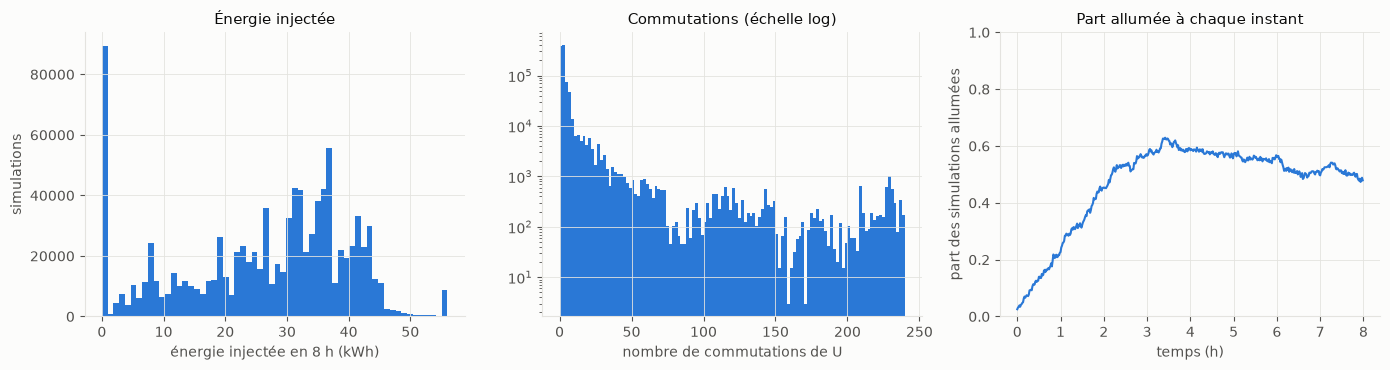

,valeur
U ≡ 0 (aucune puissance),0.08416
U ≡ 7000 (toujours allumé),0.008711
taux d'allumage moyen,0.4687
commutations : médiane,2
commutations : quantile 99 %,126


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(d["duty"] * 480 * 7000 / 60 / 1000, bins=60, color=SERIES[0])
axes[0].set_xlabel("énergie injectée en 8 h (kWh)"); axes[0].set_ylabel("simulations")
axes[0].set_title("Énergie injectée")
axes[1].hist(d["n_switches"], bins=np.arange(0, 242, 2), color=SERIES[0], log=True)
axes[1].set_xlabel("nombre de commutations de U"); axes[1].set_title("Commutations (échelle log)")
axes[2].plot(hours, r.groups["all"].on_fraction, color=SERIES[0])
axes[2].set_xlabel("temps (h)"); axes[2].set_ylabel("part des simulations allumées")
axes[2].set_ylim(0, 1); axes[2].set_title("Part allumée à chaque instant")
fig.tight_layout(); plt.show()
pd.Series({
    "U ≡ 0 (aucune puissance)": float(d["all_off"].mean()),
    "U ≡ 7000 (toujours allumé)": float(d["all_on"].mean()),
    "taux d'allumage moyen": float(d["duty"].mean()),
    "commutations : médiane": float(d["n_switches"].median()),
    "commutations : quantile 99 %": float(d["n_switches"].quantile(0.99)),
}).to_frame("valeur")

**Lecture [Mesuré].**
- **8,4 % des simulations ne reçoivent aucune puissance** et 0,9 % sont allumées en permanence. La moitié des simulations commutent au plus 2 fois en 8 h ; les blocs très courts (petits $t_{min}$) produisent jusqu'à 240 commutations.
- La part de simulations allumées dépend du temps : elle est faible au début et plus élevée ensuite. C'est une conséquence de la séquence aléatoire commune, et non une propriété physique.

**Conséquences.** La difficulté de prédiction varie a priori fortement selon l'excitation. Nous ventilons donc l'évaluation **par type d'excitation** : $U \equiv 0$, taux d'allumage, nombre de commutations. Ces descripteurs se calculent à partir de $U$, qui est une entrée du modèle : ils restent disponibles pour analyser les erreurs.

## 3. La réponse $T_{int}(t)$

### 3.1 Quelques trajectoires

**Question.** La forme des réponses correspond-elle à l'intuition physique de l'introduction : réaction immédiate de l'air, puis évolution lente pilotée par les parois ?

**Sélection.** Les six premières simulations, par indice croissant, d'un tirage uniforme de 1 000 simulations parmi le million (graine 42), fait pendant la passe complète. C'est une illustration, sans statistique tirée de ces courbes.

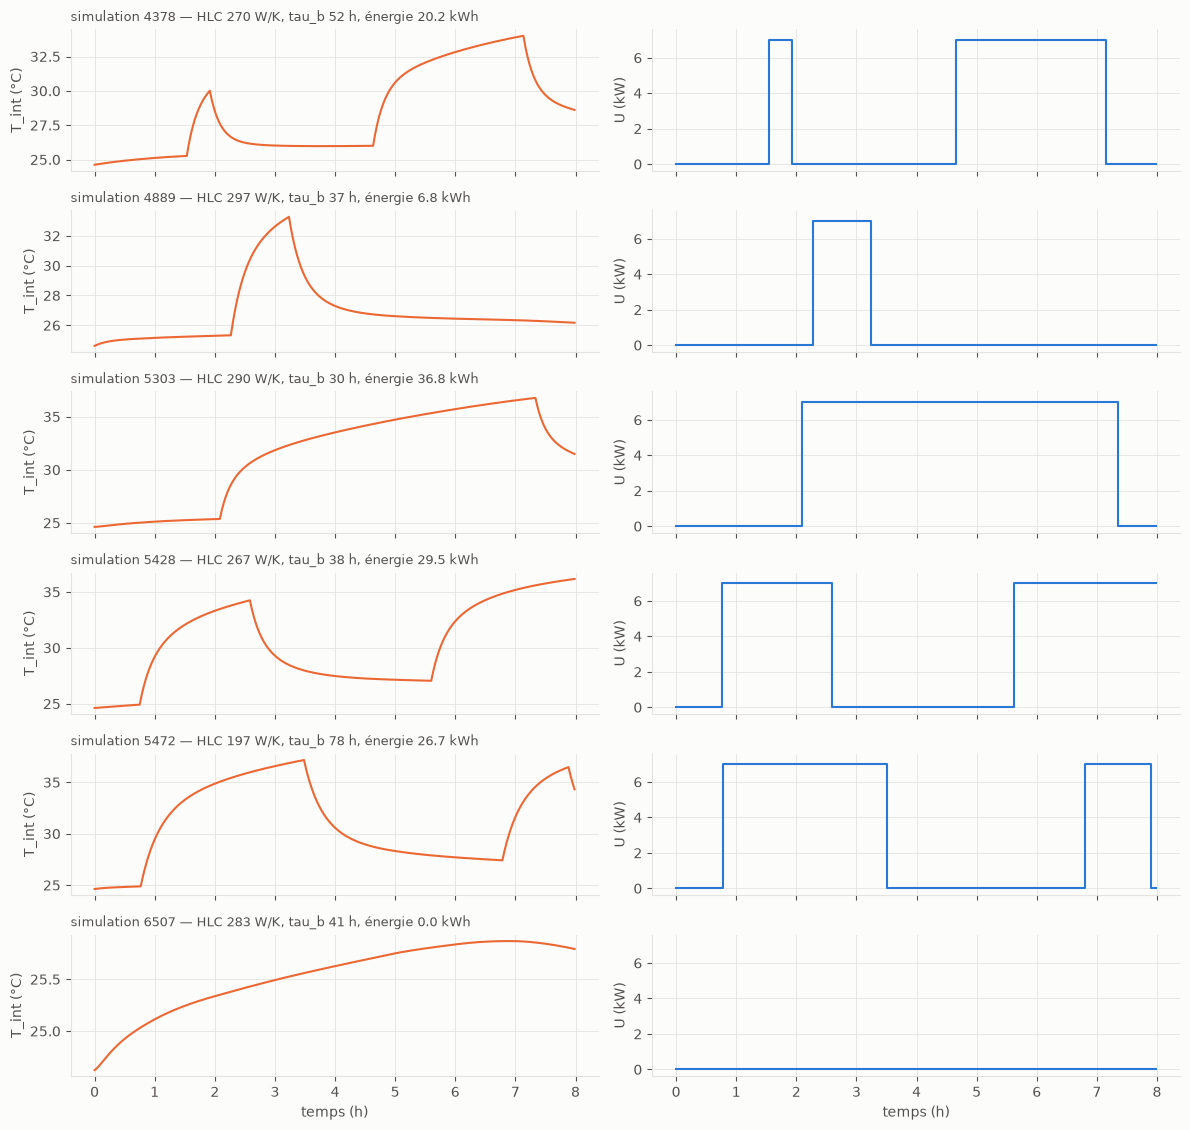

In [13]:
c = r.curves
sel = np.arange(6)
gi = c["random_idx"][sel]
labels = [f"simulation {i} — HLC {d.at[i, 'HLC']:.0f} W/K, tau_b {d.at[i, 'tau_b']:.0f} h, "
          f"énergie {d.at[i, 'duty'] * 56:.1f} kWh" for i in gi]
fig = plot_series_pairs(c["random_t"][sel], c["random_u"][sel], labels, DT_MIN)
plt.show()

**Lecture.**
- **[Mesuré]** À chaque allumage, $T$ monte vite, puis de plus en plus lentement. À l'extinction, elle redescend.
- **Interprétation physique.** C'est la signature de plusieurs constantes de temps superposées : une **rapide** (air et surfaces intérieures, quelques minutes) et des **lentes** (masse des parois, dizaines d'heures). Les courbes correspondent à l'image résistance-capacité de l'introduction.
- Même sans chauffage, $T$ dérive lentement (section 3.4).

### 3.2 Plage de températures

**Question.** Les températures atteintes sont-elles physiquement plausibles, et y a-t-il des valeurs extrêmes à traiter ?

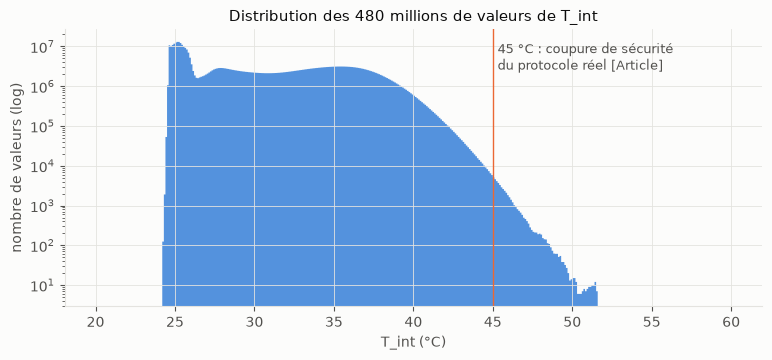

,valeur
"valeurs hors de [20, 60] °C",0
T max par simulation : médiane (°C),36.8
T max par simulation : quantile 99 % (°C),42.62
simulations dépassant 45 °C (part),0.000816


In [14]:
edges, cnt = r.t_hist_edges, r.t_hist_counts
centers = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(centers, cnt[1:-1], step="mid", color=SERIES[0], alpha=0.8, linewidth=0)
ax.set_yscale("log"); ax.set_xlabel("T_int (°C)"); ax.set_ylabel("nombre de valeurs (log)")
ax.axvline(45, color=SERIES[1], linewidth=1)
ax.text(45.3, cnt.max() / 5, "45 °C : coupure de sécurité\ndu protocole réel [Article]",
        color="#52514e", fontsize=9)
ax.set_title("Distribution des 480 millions de valeurs de T_int")
plt.show()
pd.Series({
    "valeurs hors de [20, 60] °C": int(cnt[0] + cnt[-1]),
    "T max par simulation : médiane (°C)": float(d["t_max"].median()),
    "T max par simulation : quantile 99 % (°C)": float(d["t_max"].quantile(0.99)),
    "simulations dépassant 45 °C (part)": float((d["t_max"] > 45).mean()),
}).to_frame("valeur")

**Lecture [Mesuré].**
- $T$ reste entre 24,2 et 51,5 °C.
- 0,08 % des simulations dépassent 45 °C, seuil auquel le protocole de mesure décrit dans l'article coupe le chauffage **[Article]**. Le simulateur ne l'applique pas.
- **Ordre de grandeur cohérent** : 7 kW sur un bâtiment de HLC ≈ 233 W/K donneraient à l'équilibre un écart de 7000/233 ≈ 30 K. En 8 h, loin de l'équilibre, seule une partie de cet écart est atteinte.

**Conséquence.** Aucune valeur aberrante n'est à traiter. Les quelques trajectoires au-delà de 45 °C sont physiquement possibles en simulation, même si un protocole de mesure réel les interromprait.

### 3.3 Causalité et saut à l'allumage

**Question.** À quel pas $T$ réagit-elle à un changement de $U$, et que dit l'amplitude de cette réaction ? La réponse fixe l'alignement des deux entrées.

**Intuition.** Si $U$ chauffe directement l'air, l'effet apparaît au pas même de l'allumage, et son amplitude renseigne sur la capacité thermique de l'air.

**Mesure.** Au premier allumage (pas $k$), l'accroissement de pente vaut $(T_k - T_{k-1}) - (T_{k-1} - T_{k-2})$. Il isole l'effet de la puissance injectée pendant le pas $k$. Si toute l'énergie du pas restait dans l'air, on aurait $\Delta T = P\,\Delta t / C_{air}$, d'où une **capacité apparente** $C = 7000 \times 60 / \Delta T$.

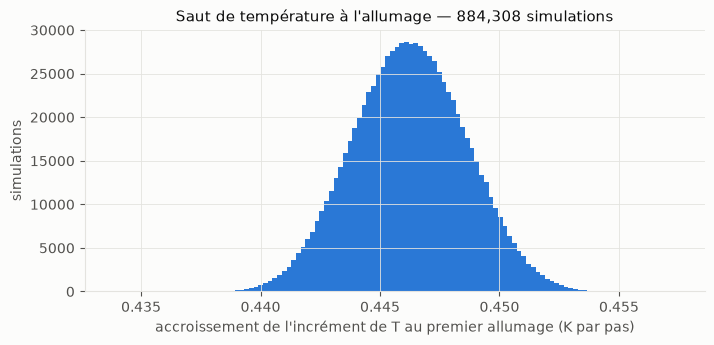

,valeur
saut médian (K),0.4462
saut : quantile 1 % (K),0.4409
saut : quantile 99 % (K),0.4516
capacité apparente médiane (MJ/K),0.9412
coefficient de variation de la capacité apparente,0.00527


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
corrélation avec le saut,-0.4563,-0.406,-0.2123,0.08941,-0.2819,-0.03399


In [15]:
jump = d["switch_on_jump"].dropna().astype(np.float64)
c_app = 7000 * 60 / jump / 1e6
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(jump, bins=120, color=SERIES[0])
ax.set_xlabel("accroissement de l'incrément de T au premier allumage (K par pas)")
ax.set_ylabel("simulations")
ax.set_title(f"Saut de température à l'allumage — {len(jump):,} simulations")
plt.show()
display(pd.Series({
    "saut médian (K)": jump.median(),
    "saut : quantile 1 % (K)": jump.quantile(0.01),
    "saut : quantile 99 % (K)": jump.quantile(0.99),
    "capacité apparente médiane (MJ/K)": c_app.median(),
    "coefficient de variation de la capacité apparente": c_app.std() / c_app.mean(),
}).to_frame("valeur"))
d.loc[jump.index, list(TARGET_LABELS)].astype(np.float64).corrwith(jump).to_frame("corrélation avec le saut").T

**Lecture.**
- **[Mesuré]** $T$ réagit **dès le pas où $U$ s'allume**. Le saut est d'environ 0,45 K par minute, contre quelques millièmes de K avant l'allumage. Autrement dit, $U_k$ agit sur l'intervalle qui se termine à l'instant $k$ et se voit déjà dans $T_k$.
- **[Mesuré]** Le saut est **presque identique pour toutes les simulations**. La capacité apparente vaut 0,94 MJ/K, avec un coefficient de variation de 0,5 %.
- **[Hypothèse H10]** La capacité du nœud d'air (air et mobilier) n'est pas, ou très peu, tirée aléatoirement. Dans l'article, le tirage Monte-Carlo porte sur les paramètres thermophysiques des parois **[Article]**.
- **[Mesuré]** La petite variation restante est corrélée au HLC (−0,46). Interprétation : une partie de la chaleur quitte déjà l'air vers les surfaces pendant la première minute.

**Conséquences.** Nous alignons $T_k$ et $U_k$ **sans décalage**. Les premières minutes après chaque commutation portent l'information sur les échanges rapides, et un sous-échantillonnage au quart d'heure les effacerait. La résolution d'une minute sert donc de référence, et toute résolution plus grossière envisagée en modélisation lui est comparée.

### 3.4 La réponse libre ($U \equiv 0$)

**Question.** Sans puissance appliquée, que fait $T$, et que révèle-t-elle du bâtiment ? 8,4 % des simulations sont dans ce cas (section 2.4).

**Sélection pour la figure de droite.** Les 400 premières simulations $U \equiv 0$ du batch 1. La bande de gauche et les corrélations portent sur les 84 164 simulations $U \equiv 0$ du million.

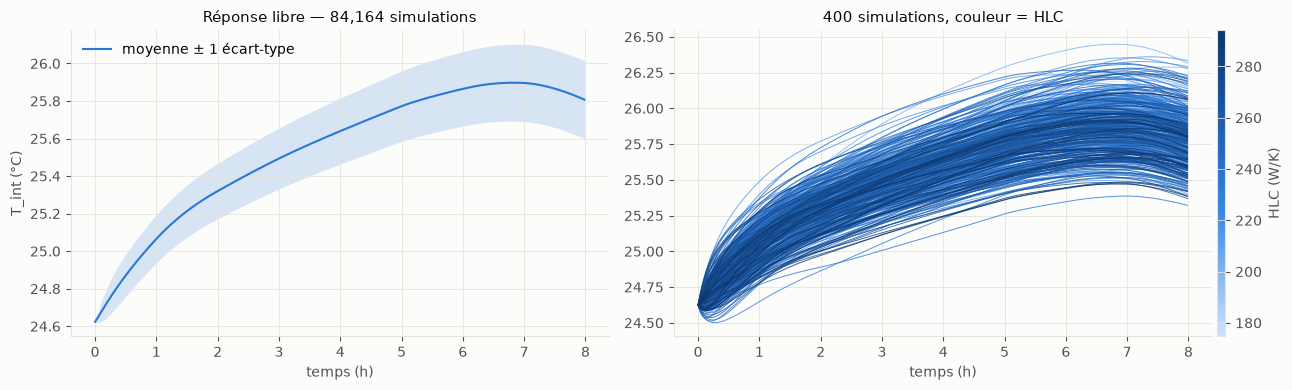

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
|corr| max sur t,0.1829,0.2365,0.06927,0.19,0.3134,0.2142
écart-type de T à 8 h (K),0.2074,0.2074,0.2074,0.2074,0.2074,0.2074


In [16]:
g = r.groups["free"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_band(axes[0], hours, g.t_mean, g.t_std, SERIES[0], "moyenne ± 1 écart-type")
axes[0].set_xlabel("temps (h)"); axes[0].set_ylabel("T_int (°C)")
axes[0].set_title(f"Réponse libre — {g.n:,} simulations"); axes[0].legend(loc="upper left")
free_hlc = d.loc[c["free_idx"], "HLC"].to_numpy()
plot_curves_by_value(axes[1], hours, c["free_t"], free_hlc, "HLC (W/K)")
axes[1].set_xlabel("temps (h)"); axes[1].set_title("400 simulations, couleur = HLC")
fig.tight_layout(); plt.show()
pd.DataFrame({"|corr| max sur t": np.nanmax(np.abs(g.corr_t_targets), axis=0),
              "écart-type de T à 8 h (K)": g.t_std[-1]}, index=TARGET_LABELS).T

**Lecture.**
- **[Mesuré]** Sans aucune puissance, $T$ monte d'environ 1,2 K en 8 h : de 24,6 à 25,8 °C en moyenne. Les trajectoires s'écartent peu les unes des autres (écart-type de 0,2 K à 8 h), et leur corrélation avec les cibles reste faible (au plus 0,31, pour $\tau_n$).
- **[Hypothèse H3, H4]** Cette dérive commune vient des conditions aux limites (météo, zones voisines), non fournies et vraisemblablement identiques pour toutes les simulations, et d'un état initial des parois plus chaud que l'air. Dans l'article, cet état initial est tiré au hasard autour d'un gradient linéaire **[Article]**. La dispersion non expliquée par les cibles est cohérente avec un tel tirage.

**Conséquences.** Les 8,4 % de simulations $U \equiv 0$ sont **presque non identifiables** : nous anticipons des erreurs nettement plus élevées sur ce sous-ensemble. Nous les conservons à l'entraînement comme au test, car elles font partie de la distribution des données. Leurs performances sont rapportées séparément dans l'évaluation, afin que les métriques globales ne masquent pas cette limite.

### 3.5 Résolution et arrondi

**Question.** Le code de l'énoncé arrondit $T$ à 0,01 °C et $U$ à 0,1 W **[Assessment]**, alors que les données brutes ne le sont pas. Quelle information cet arrondi efface-t-il ?

In [17]:
pd.Series({
    "incréments |ΔT| < 0,005 °C, toutes simulations": float(d["frac_sub_quantum_dt"].mean()),
    "idem, simulations U ≡ 0": float(d.loc[d["all_off"], "frac_sub_quantum_dt"].mean()),
    "idem, simulations avec puissance": float(d.loc[~d["all_off"], "frac_sub_quantum_dt"].mean()),
    "U modifié par l'arrondi à 0,1 W": "non (U ∈ {0, 7000})",
}).to_frame("valeur")

,valeur
"incréments |ΔT| < 0,005 °C, toutes simulations",0.2291
"idem, simulations U ≡ 0",0.8616
"idem, simulations avec puissance",0.171
"U modifié par l'arrondi à 0,1 W","non (U ∈ {0, 7000})"


**Lecture [Mesuré].**
- **Pour $U$, l'arrondi ne change rien**, puisque $U$ ne vaut que 0 ou 7000.
- **Pour $T$, 23 % des incréments d'une minute sont inférieurs au demi-quantum** (86 % dans la réponse libre) : l'arrondi les efface, et la courbe devient un escalier. L'écart entre bâtiments (≈ 0,2 K à 8 h en réponse libre) reste en revanche 20 fois plus grand que le quantum.

**Conséquences.**
- Nous appliquons l'arrondi de l'énoncé **à l'identique** à l'entraînement et à l'évaluation : il joue le rôle d'une quantification de capteur.
- Toute grandeur calculée par différences finies sur $T$ arrondie hérite de cet effet d'escalier, et est donc très bruitée.
- L'article bruite en outre ses signaux d'entraînement avec un bruit gaussien calibré sur ses capteurs, dont la précision typique est de ±0,25 °C **[Article]**. L'énoncé ne le prévoit pas, et nous n'en ajoutons pas à ce stade.

## 4. Les cibles

### 4.1 Distributions

**Question.** Quelles échelles et quelles formes de distribution ont les six cibles ? Elles déterminent la normalisation et la forme de la perte.

In [18]:
an.target_summary(d)

,count,mean,std,min,1%,50%,99%,max,asymétrie,asymétrie de log,unité
HLC,1e+06,232.9,31.33,111.4,166.5,231.8,307.9,368,0.179,-0.1801,W/K
HLC_mit,1e+06,120.5,26.26,42.84,69.37,118.9,183.5,231.5,0.2815,-0.2307,W/K
HLC_ext,1e+06,112.4,17.11,52.65,75.65,112.2,152.2,185.9,0.1011,-0.2991,W/K
tau_b,1e+06,50,10.1,20.2,31.53,48.82,78.76,122.9,0.713,0.11,h
tau_n,1e+06,11.04,2.009,5.172,7.404,10.79,16.83,25.84,0.7528,0.205,h
tau_inf,1e+06,31.23,7.53,10.48,18.08,30.2,53.38,93.12,0.8486,0.1311,h


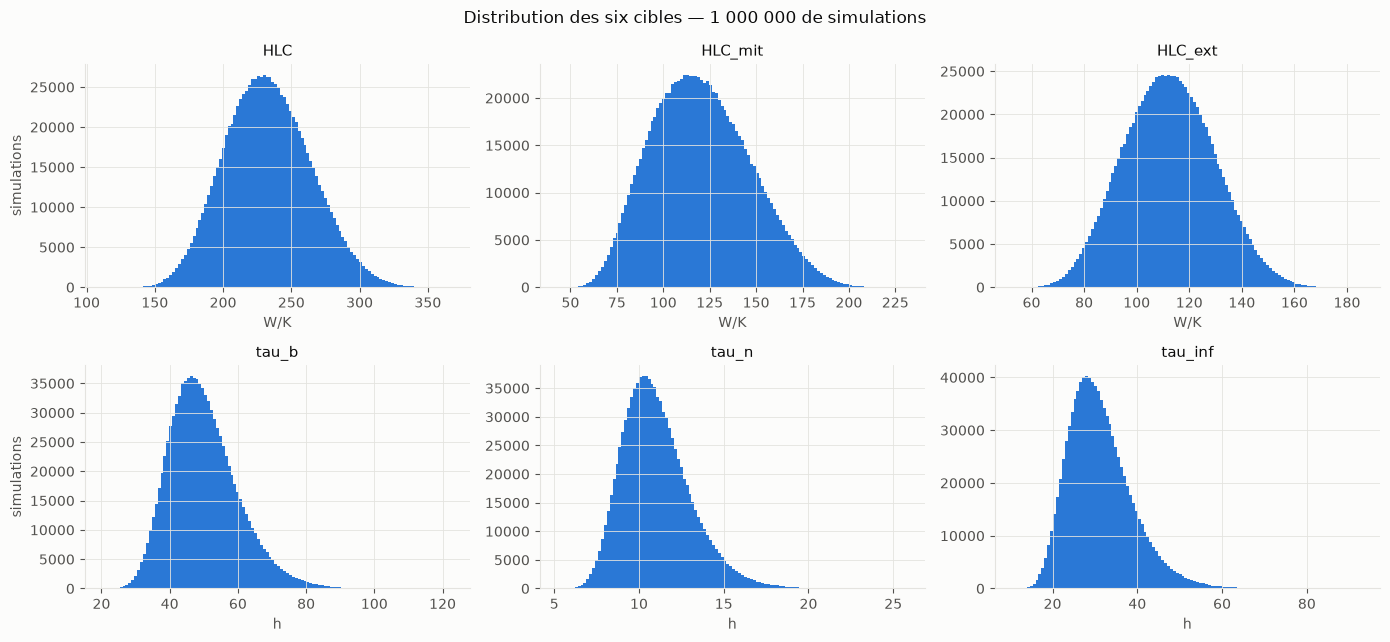

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
units = ["W/K"] * 3 + ["h"] * 3
for ax, lab, unit in zip(axes.ravel(), TARGET_LABELS, units):
    ax.hist(d[lab], bins=120, color=SERIES[0])
    ax.set_title(lab); ax.set_xlabel(unit)
axes[0, 0].set_ylabel("simulations"); axes[1, 0].set_ylabel("simulations")
fig.suptitle("Distribution des six cibles — 1 000 000 de simulations", color="#0b0b0b")
fig.tight_layout(); plt.show()

**Lecture [Mesuré].**
- **Les échelles sont très différentes** : HLC ≈ 233 ± 31 W/K, contre $\tau_n$ ≈ 11 ± 2 h.
- Les distributions sont unimodales, en cloche, sans valeur aberrante. Dans l'article, les paramètres physiques sont tirés uniformément, à ±60 % autour du nominal **[Article]**. Si ce jeu a été généré de la même façon, chaque cible combine de nombreux paramètres uniformes, ce qui explique cette forme en cloche.
- **Les constantes de temps sont asymétriques vers la droite** (asymétrie 0,71 à 0,85). En logarithme, cette asymétrie tombe sous 0,21.

**Conséquences.** Nous normalisons chaque cible séparément : une perte non pondérée serait dominée par les cibles en W/K. Nous retenons une **transformation logarithmique des $\tau$**, justifiée par leur asymétrie ; la section 4.3 en donne aussi une raison physique.

### 4.2 La contrainte $HLC = HLC_{ext} + HLC_{mit}$

**Question.** La contrainte de somme imposée par l'énoncé est-elle exacte dans les données, ou seulement approchée ? La réponse détermine la façon de l'intégrer au modèle.

In [20]:
an.constraint_residuals(d).to_frame("valeur")

,valeur
résidu nul en float32 (part),0.7493
"|résidu| max en float32, en ulp de HLC",1
|résidu| max (W/K),2.289e-05
|résidu| relatif max,8.94e-08


**Lecture [Mesuré].** La contrainte est **exacte à la précision de stockage près**. Le résidu est nul dans 75 % des cas en float32 et ne dépasse jamais 1 ulp, soit l'écart entre deux nombres float32 consécutifs.

**Conséquence.** La contrainte est une identité, pas une approximation. Elle peut donc être **imposée par construction**, par exemple en prédisant les deux composantes et en définissant HLC comme leur somme. Son respect par les prédictions fait partie des métriques rapportées.

### 4.3 Cohérence physique et structure des cibles

**Question.** Les cibles sont-elles physiquement cohérentes entre elles, et quelles relations les lient ? Des relations fortes indiquent qu'un modèle peut partager l'information entre sorties.

In [21]:
an.ordering_checks(d).to_frame("valeur")

,valeur
tau_n < tau_inf (part),1
tau_inf < tau_b (part),1
tau_n / tau_inf : min,0.1829
tau_n / tau_inf : max,0.6219
tau_inf / tau_b : min,0.4351
tau_inf / tau_b : max,0.7915
part de HLC_mit dans HLC : min,0.2505
part de HLC_mit dans HLC : max,0.7628


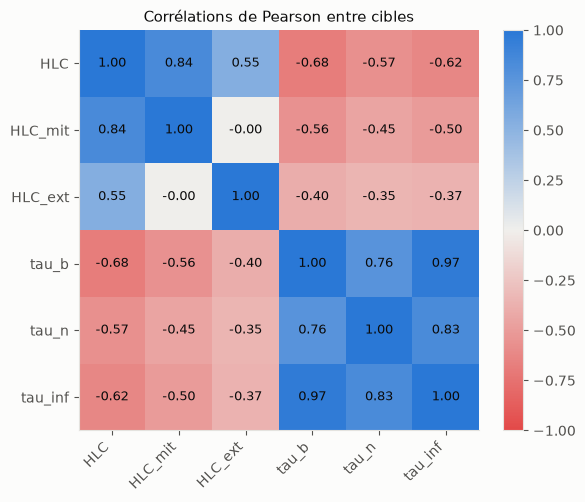

,C moyenne (MJ/K),C écart-type (MJ/K),"corr(C, HLC)","corr(tau, HLC)","corr(tau, 1/HLC)"
constante,,,,,
tau_b,41.15,5.841,-0.01656,-0.6835,0.6956
tau_n,9.129,1.349,0.2194,-0.5653,0.5718
tau_inf,25.66,4.679,-0.07511,-0.6196,0.6313


In [22]:
corr = d[list(TARGET_LABELS)].astype(np.float64).corr()
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(corr, cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(6), TARGET_LABELS, rotation=45, ha="right"); ax.set_yticks(range(6), TARGET_LABELS)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=9, color="#0b0b0b")
ax.grid(False); ax.set_title("Corrélations de Pearson entre cibles")
plt.colorbar(im, ax=ax, fraction=0.046); plt.show()
an.time_constant_capacities(d)

**Lecture.**
- **[Mesuré] L'ordre $\tau_n < \tau_\infty < \tau_b$ est vérifié dans 100 % des simulations.** C'est l'ordre attendu d'après les définitions de l'énoncé **[Assessment]**, ce qui conforte l'ordre des colonnes CDT **[Hypothèse H8]** :
  - $\tau_n$ mesure la persistance de la fraîcheur après un refroidissement de l'air appliqué pendant $t_0$ = 8 h. En 8 h, le froid ne pénètre que partiellement dans les parois : seule une partie de l'inertie intervient ;
  - $\tau_\infty$ est la limite de $\tau_n$ quand la durée du refroidissement tend vers l'infini. Le froid a alors pénétré davantage, d'où $\tau_n < \tau_\infty$ ;
  - $\tau_b$ décrit la relaxation après que **toute** la masse du bâti a été portée à un écart de température uniforme. Toute l'inertie intervient, d'où la plus grande constante.
- **[Mesuré] $HLC_{mit}$ et $HLC_{ext}$ sont décorrélés** (−0,001). Les deux types de frontière ont été tirés indépendamment. $HLC_{mit}$ varie davantage (écart-type 26 W/K contre 17) et représente entre 25 et 76 % du total.
- **[Mesuré] Les constantes de temps se comportent comme $\tau = C/HLC$.** La capacité apparente $C_b = \tau_b \times HLC$ (≈ 41 MJ/K) est **décorrélée du HLC** (−0,02). La corrélation négative entre $\tau_b$ et HLC (−0,68) vient donc presque entièrement du facteur $1/HLC$. C'est aussi vrai pour $\tau_\infty$ ($C_\infty$ : −0,08). Ça l'est moins pour $\tau_n$ ($C_n$ : +0,22), dont la définition dépend de la profondeur de pénétration en 8 h, et pas seulement de la masse totale.
- **[Mesuré]** $\tau_b$ et $\tau_\infty$ sont presque redondants (0,97). Le rapport $\tau_\infty/\tau_b$ reste entre 0,43 et 0,79.

**Conséquences.**
- Les six cibles ne sont pas indépendantes. En particulier, $\log \tau = \log C - \log HLC$ : en espace logarithmique, chaque constante de temps se décompose en une capacité et le HLC. **Un modèle multi-sorties peut exploiter ce partage d'information.**
- L'ordre $\tau_n < \tau_\infty < \tau_b$ et la contrainte de somme servent de **contrôles de cohérence physique** des prédictions.

### 4.4 Fenêtre d'observation et constantes de temps

**Question.** Les 8 h observées sont-elles assez longues pour « voir » les constantes de temps ? Le HLC est un gain d'équilibre : pour le lire directement sur $T$, il faudrait observer le régime permanent, qui n'est atteint qu'après plusieurs constantes de temps.

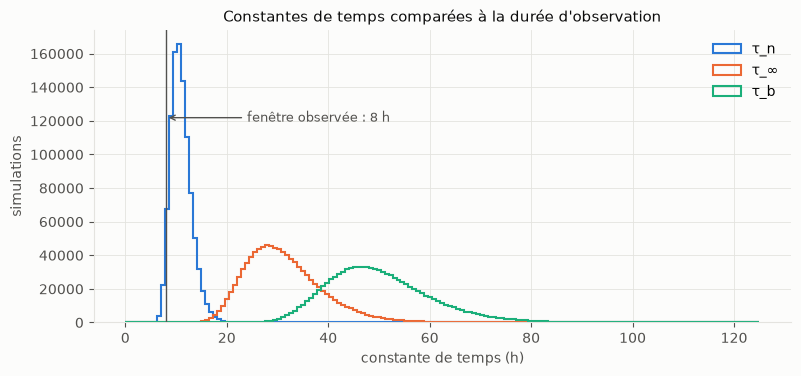

,médiane de tau (h),fenêtre / tau : médiane,fenêtre / tau : min,fenêtre / tau : max,part avec tau < fenêtre
constante,,,,,
tau_b,48.82,0.1639,0.0651,0.3961,0
tau_n,10.79,0.7413,0.3096,1.547,0.03466
tau_inf,30.2,0.2649,0.08591,0.763,0


In [23]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 125, 160)
for k, (lab, name) in enumerate([("tau_n", "τ_n"), ("tau_inf", "τ_∞"), ("tau_b", "τ_b")]):
    ax.hist(d[lab], bins=bins, histtype="step", linewidth=1.5, color=SERIES[k], label=name)
ax.axvline(WINDOW_H, color="#52514e", linewidth=1)
ax.annotate("fenêtre observée : 8 h", xy=(WINDOW_H, ax.get_ylim()[1] * 0.7), xytext=(24, ax.get_ylim()[1] * 0.7),
            color="#52514e", fontsize=9, va="center", arrowprops=dict(arrowstyle="->", color="#52514e"))
ax.set_xlabel("constante de temps (h)"); ax.set_ylabel("simulations"); ax.legend()
ax.set_title("Constantes de temps comparées à la durée d'observation")
plt.show()
an.information_window(d, WINDOW_H)

**Lecture [Mesuré].**
- La fenêtre de 8 h est plus courte que $\tau_b$ et $\tau_\infty$ dans toutes les simulations. Elle est même plus courte que $\tau_n$ dans 96,5 % des cas.
- En médiane, la fenêtre ne couvre qu'environ 16 % de $\tau_b$.
- Le bâtiment n'atteint donc **jamais le régime permanent**. Or le HLC est par définition un gain statique, c'est-à-dire la réponse une fois l'équilibre atteint ($HLC = 1/[S]_{11}$, **[Article]**).

**Conséquence.** Toutes les cibles sont à **inférer à partir du régime transitoire** : c'est la difficulté centrale du problème, et la raison pour laquelle coEnergy apprend sur des simulations plutôt que d'attendre l'équilibre **[Article]**. Les constantes de temps longues ne sont vues que par le début de la réponse ; nous anticipons qu'elles soient les plus difficiles à prédire, ce que la section 5 confirme.

## 5. Quelle information $T_{int}(t)$ contient-elle sur les cibles ?

**Question.** Avant de modéliser, peut-on mesurer combien $T(t)$ varie avec chaque cible quand l'excitation est fixée ? La section 2.3 fournit des milliers de bâtiments soumis **exactement au même signal $U$** : entre eux, seuls le bâtiment et son état initial changent.

### 5.1 Même excitation, bâtiments différents

**Sélection pour les courbes.** Les 400 premières simulations du batch 1 portant le signal $U$ non nul le plus fréquent (`pattern_1`). Les corrélations de la section 5.2 sont calculées sur toutes les simulations de chaque groupe, soit 14 670 pour `pattern_1`.

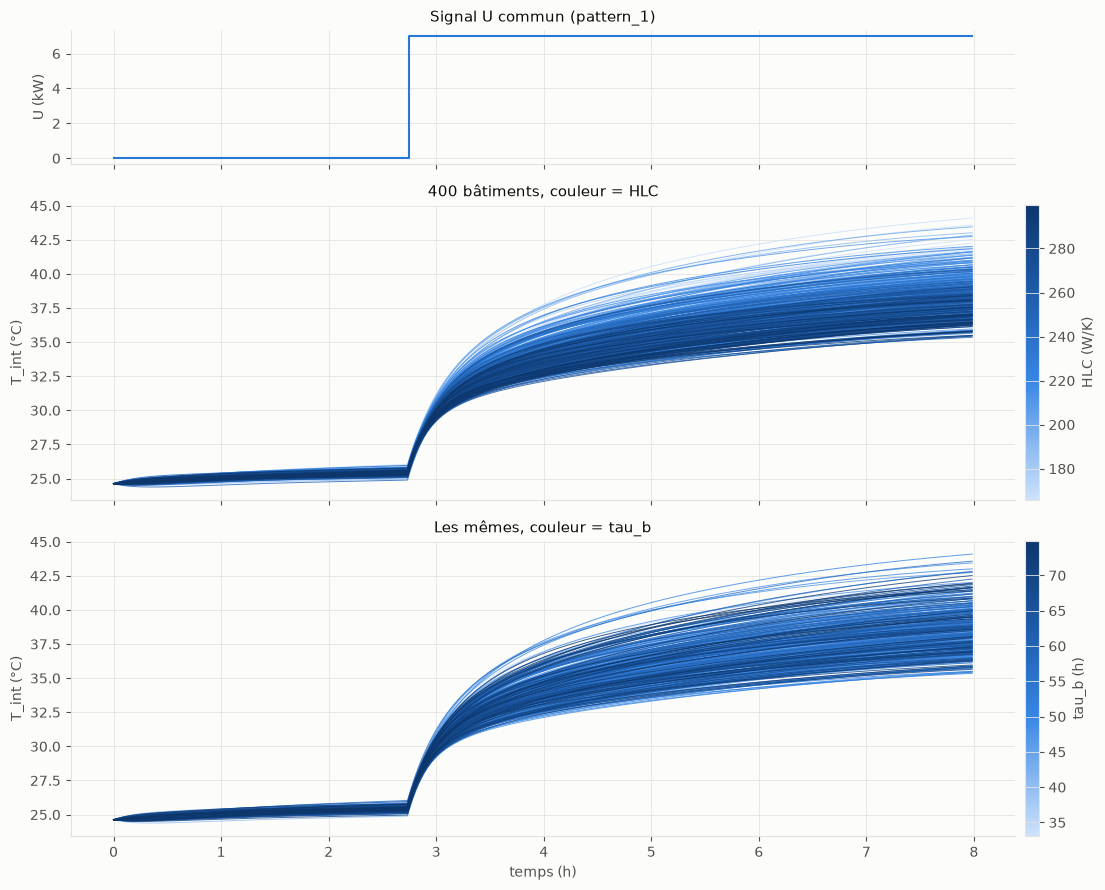

In [24]:
idx1 = c["pattern_1_idx"]
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, gridspec_kw={"height_ratios": [1, 2.2, 2.2]})
axes[0].step(hours, r.group_patterns["pattern_1"] / 1000, where="post", color=SERIES[0])
axes[0].set_ylabel("U (kW)"); axes[0].set_title("Signal U commun (pattern_1)")
plot_curves_by_value(axes[1], hours, c["pattern_1_t"], d.loc[idx1, "HLC"].to_numpy(), "HLC (W/K)")
axes[1].set_ylabel("T_int (°C)"); axes[1].set_title("400 bâtiments, couleur = HLC")
plot_curves_by_value(axes[2], hours, c["pattern_1_t"], d.loc[idx1, "tau_b"].to_numpy(), "tau_b (h)")
axes[2].set_ylabel("T_int (°C)"); axes[2].set_title("Les mêmes, couleur = tau_b"); axes[2].set_xlabel("temps (h)")
fig.tight_layout(); plt.show()

### 5.2 Corrélation entre $T(t)$ et les cibles au cours du temps

Pour chaque groupe à excitation identique, nous calculons la corrélation de Pearson entre $T(t)$ et chaque cible, à chaque instant, à partir des sommes exactes accumulées pendant la passe. Deux groupes sont tracés ici : `pattern_1` et la réponse libre `free`. Le tableau donne le maximum de |corr| pour tous les groupes suivis.

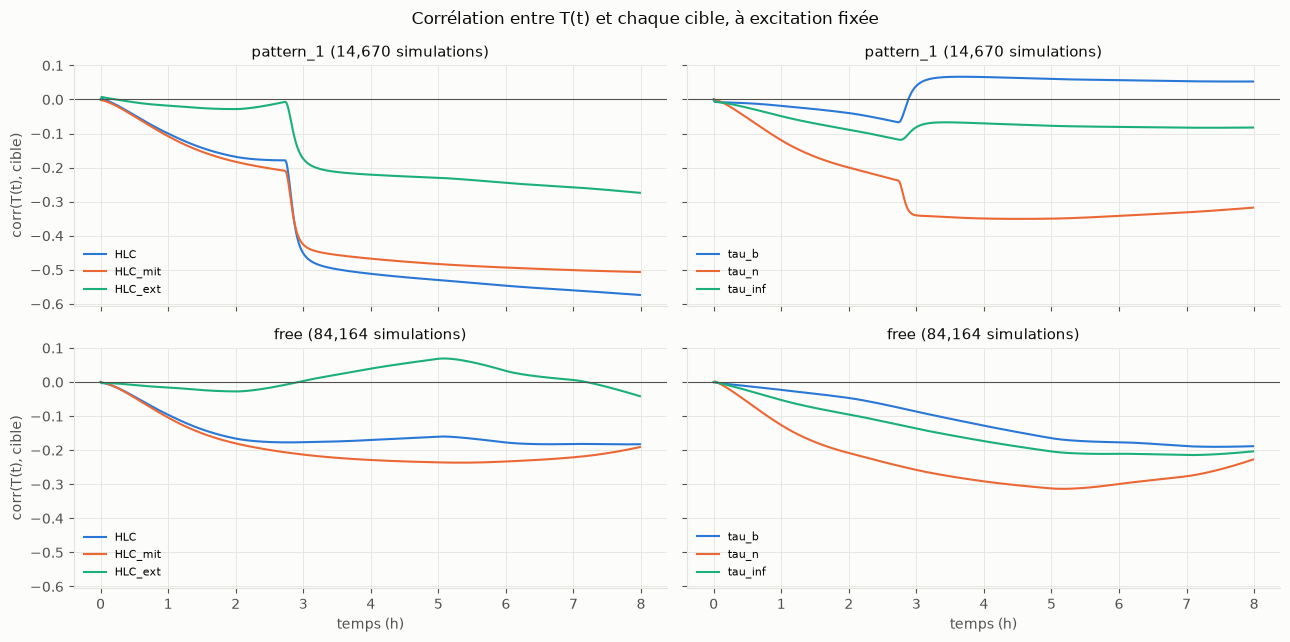

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,n
all,0.1143,0.1022,0.05515,0.007152,0.07849,0.02594,1000000
free,0.1829,0.2365,0.06927,0.19,0.3134,0.2142,84164
pattern_1,0.5738,0.5065,0.274,0.06701,0.3505,0.1184,14670
pattern_2,0.5742,0.5061,0.27,0.06714,0.3712,0.1204,14600
pattern_3,0.5734,0.5106,0.2709,0.06096,0.3646,0.1092,8850
pattern_4,0.5912,0.5197,0.2907,0.07573,0.3558,0.1037,8711
pattern_5,0.5654,0.4968,0.2749,0.07736,0.3623,0.1269,8751
pattern_6,0.5528,0.4892,0.2609,0.1068,0.3725,0.1566,8759
pattern_7,0.5677,0.5028,0.2599,0.0813,0.3719,0.1339,8818
pattern_8,0.5701,0.4993,0.2654,0.1068,0.3791,0.1602,5903


In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey=True)
families = [("HLC", "HLC_mit", "HLC_ext"), ("tau_b", "tau_n", "tau_inf")]
for row, gname in enumerate(["pattern_1", "free"]):
    gs = r.groups[gname]
    for col, fam in enumerate(families):
        ax = axes[row, col]
        for k, lab in enumerate(fam):
            ax.plot(hours, gs.corr_t_targets[:, TARGET_LABELS.index(lab)], color=SERIES[k], label=lab)
        ax.axhline(0, color="#52514e", linewidth=0.8)
        ax.set_title(f"{gname} ({gs.n:,} simulations)")
        ax.legend(loc="lower left", fontsize=8)
for ax in axes[:, 0]: ax.set_ylabel("corr(T(t), cible)")
for ax in axes[1]: ax.set_xlabel("temps (h)")
fig.suptitle("Corrélation entre T(t) et chaque cible, à excitation fixée", color="#0b0b0b")
fig.tight_layout(); plt.show()
pd.DataFrame({name: np.nanmax(np.abs(gs.corr_t_targets), axis=0) for name, gs in r.groups.items()},
             index=TARGET_LABELS).T.assign(n=[gs.n for gs in r.groups.values()])

**Lecture [Mesuré].**
- **À excitation fixée, un HLC plus élevé donne une température plus basse.** Les courbes se rangent clairement par couleur, et la corrélation atteint −0,55 à −0,59 selon le groupe, dans les 8 groupes de signal $U$ suivis. **L'information arrive surtout avec l'excitation.** Pendant la phase sans chauffage de `pattern_1` (0 à 2,75 h), la corrélation avec le HLC plafonne à −0,18, comme en réponse libre. Elle passe à −0,45 moins d'une heure après l'allumage, puis continue de croître lentement. $HLC_{ext}$ n'apparaît qu'après l'allumage.
- **$HLC_{mit}$ (≈ 0,5) est plus visible que $HLC_{ext}$ (≈ 0,27).** Cela est cohérent avec sa plus grande variance.
- **$\tau_b$ et $\tau_\infty$ ne sont presque pas visibles linéairement** (≤ 0,16) : les courbes colorées par $\tau_b$ ne se rangent pas. $\tau_n$, la plus courte, l'est davantage (0,35 à 0,38).
- **Sur l'ensemble des simulations, excitations mélangées** (groupe `all`), aucune corrélation ne dépasse 0,11. La variance de $T$ est dominée par l'excitation.
- Ces corrélations ne mesurent que l'**information linéaire, instant par instant**. Ce sont des bornes basses : un modèle combinant toute la trajectoire peut extraire davantage, par exemple $\tau_b$ par l'intermédiaire de sa forte corrélation avec le HLC (section 4.3).

**Conséquences.**
- **$U$ est une entrée indispensable** : sans elle, la variabilité due à l'excitation masque celle du bâtiment.
- Nous en tirons une hiérarchie de difficulté attendue : HLC et $HLC_{mit}$, puis $HLC_{ext}$ et $\tau_n$, puis $\tau_\infty$ et $\tau_b$. Elle sert de grille de lecture pour l'analyse d'erreurs, et non de résultat.

### 5.3 Indépendance entre excitation et bâtiment

**Question.** Les paramètres d'excitation ont-ils été tirés indépendamment des bâtiments ? Sinon, un modèle pourrait apprendre la cible à partir de l'excitation seule.

In [26]:
an.excitation_target_correlation(d)

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
prbs_min_duration_hours,0.001448,0.001676,7.951e-05,-0.0008331,-0.0009021,-0.0006561
prbs_probability_on,0.002662,0.002747,0.00066,-0.002837,-0.00132,-0.002657
duty,0.002043,0.002019,0.0006418,-0.002515,-0.001778,-0.002566
n_switches,-0.0008352,-6.258e-05,-0.001433,-0.000557,-0.0004434,-0.000753


**Lecture [Mesuré].** Toutes les corrélations sont inférieures à 0,003 en valeur absolue : l'excitation est **indépendante du bâtiment**.

**Conséquence.** $U$ ne transporte aucune information sur les cibles par elle-même : il n'y a pas de fuite par l'excitation. Nous excluons `solicitation` des entrées du modèle ; il sert seulement à l'analyse.

## 6. Indépendance des simulations, fuite et homogénéité des batchs

**Question.** Un même bâtiment apparaît-il dans plusieurs simulations ? Si oui, il pourrait se retrouver à la fois en entraînement et en test. Et les batchs sont-ils interchangeables ?

In [27]:
pd.Series({
    "vecteurs de cibles distincts": d["y_hash"].nunique(),
    "trajectoires T distinctes": d["t_hash"].nunique(),
    "signaux U distincts": d["u_hash"].nunique(),
    "vecteurs de cibles partagés entre batchs": int((d.groupby("y_hash")["batch"].nunique() > 1).sum()),
}).to_frame("valeur")

,valeur
vecteurs de cibles distincts,1000000
trajectoires T distinctes,1000000
signaux U distincts,2798
vecteurs de cibles partagés entre batchs,0


In [28]:
cols = list(TARGET_LABELS) + ["prbs_min_duration_hours", "prbs_probability_on", "duty", "all_off", "t_end"]
z = an.batch_homogeneity(d, cols)
pd.DataFrame({"|z| max sur les 20 batchs": z.abs().max(), "batchs avec |z| > 3": (z.abs() > 3).sum()}).T

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,prbs_min_duration_hours,prbs_probability_on,duty,all_off,t_end
|z| max sur les 20 batchs,2.237,2.251,1.993,1.503,2.442,1.456,3.288,1.573,1.988,2.655,2.326
batchs avec |z| > 3,0,0,0,0,0,0,1,0,0,0,0


**Lecture [Mesuré].**
- **Les 1 000 000 de vecteurs de cibles sont tous distincts**, de même que les trajectoires de température. Chaque simulation correspond à un bâtiment différent. Nous supposons que des cibles distinctes impliquent des bâtiments distincts **[Hypothèse H5]**.
- Les excitations, elles, sont partagées (section 2.3).
- **Les moyennes par batch ne s'écartent pas plus de la moyenne globale que ce qu'expliquent les fluctuations d'échantillonnage.** Sur 220 z-scores (20 batchs × 11 grandeurs), un seul dépasse 3 (3,29, pour $t_{min}$ dans un batch). Pour des tirages d'une même distribution, environ 0,6 dépassement est attendu par hasard. Les batchs sont interchangeables : ils ne correspondent ni à des campagnes ni à des régimes différents.

**Conséquences.**
- **Un découpage aléatoire par simulation ne fait pas fuir d'information sur le bâtiment.**
- Le seul partage entre entraînement et test concerne l'excitation, d'où le **test complémentaire groupé par signal $U$** annoncé en 2.3, qui mesure la généralisation à des excitations nouvelles.
- Des batchs entiers peuvent servir de validation et de test sans biais, ce qui s'accorde avec un chargement batch par batch.

## 7. Synthèse

### 7.1 Constats

1. **Données propres et homogènes.** 20 batchs de structure identique, aucune valeur manquante, batchs interchangeables.
2. **Séries.** 480 pas de **1 minute (8 h)** ; le pas est déduit des durées PRBS et non fourni. $T(0) = 24{,}624$ °C pour toutes les simulations.
3. **Excitation.** $U$ est une puissance en W, **binaire, 0 ou 7000 W**, exclusivement de type PRBS. Elle est générée à partir d'une séquence aléatoire commune (graine 42), d'où **2 798 signaux distincts seulement**.
4. **Excitations pauvres.** 8,4 % des simulations ne reçoivent aucune puissance ($U \equiv 0$) ; leur réponse libre ne porte presque pas d'information sur le bâtiment.
5. **Réponse.** $T$ réagit dès le pas d'allumage de $U$, sans retard. Le saut à l'allumage révèle une capacité d'air quasi constante (≈ 0,94 MJ/K).
6. **Cibles.** Échelles très différentes. Les $\tau$ sont asymétriques, mais à peu près symétriques en logarithme. **La contrainte de somme est exacte**, et **$\tau_n < \tau_\infty < \tau_b$ toujours**.
7. **Structure des cibles.** Les constantes de temps se comportent comme $\tau = C/HLC$ : $\tau_b \cdot HLC$ est décorrélé du HLC. $HLC_{mit}$ et $HLC_{ext}$ sont indépendants. $\tau_b$ et $\tau_\infty$ sont quasi redondants (0,97).
8. **Régime transitoire.** La fenêtre de 8 h est bien plus courte que les constantes de temps ; le régime permanent n'est jamais atteint.
9. **Information.** À excitation fixée, $T$ est nettement liée au HLC (|r| jusqu'à 0,57), faiblement à $\tau_b$ et $\tau_\infty$ (≤ 0,16, en linéaire). Sans conditionner sur $U$, le lien disparaît.
10. **Indépendance.** Chaque simulation est un bâtiment distinct, et l'excitation est indépendante du bâtiment. Seules les excitations sont partagées entre simulations.

### 7.2 Hypothèses

| # | Observation [Mesuré] | Hypothèse | Impact si elle est fausse |
|---|---|---|---|
| H1 | Plus courte série de U ≥ $t_{min}$ en minutes, à un pas près ; intégration au pas d'une minute dans l'article | 1 pas = 1 min, fenêtre de 8 h | Seules les unités de temps des interprétations changent (heures, capacité apparente). Le modèle, qui travaille en pas, n'est pas affecté. |
| H2 | U ∈ {0, 7000} = `max_power_wat` ; réponse de T au même pas | U est la puissance brute (W) injectée dans le nœud d'air de la zone | Lecture physique de U erronée. Les entrées restent celles de l'énoncé, donc le modèle n'est pas affecté. |
| H3 | T(0) identique ; dérive libre commune ; aucun champ météo | Conditions aux limites (météo, zones voisines) identiques pour toutes les simulations et inconnues | Si elles varient, c'est une entrée cachée qui crée une erreur irréductible. Un modèle entraîné ici ne vaut de toute façon que pour ces conditions. |
| H4 | Dispersion de la réponse libre peu expliquée par les cibles | État initial des parois tiré au hasard, comme dans l'article | Sans effet sur la méthode. Cela modifierait seulement l'explication de l'erreur résiduelle. |
| H5 | 1 000 000 de vecteurs de cibles distincts | Un bâtiment différent par simulation | Si deux simulations partageaient un bâtiment avec des cibles légèrement différentes, le découpage aléatoire laisserait fuir de l'information. C'est peu plausible. |
| H6 | Frontière nette $p_{on}$ = 0,88227 ; 2 798 signaux | Séquence aléatoire commune ; U est une fonction de $(t_{min}, p_{on})$ | Seule la justification du test groupé par signal U est concernée. |
| H7 | `average_fluctuation_wat` = 0 partout, absent de l'annexe | Paramètre inactif dans ce jeu | Aucun, puisqu'il ne varie pas. |
| H8 | $\tau_n < \tau_\infty < \tau_b$ dans 100 % des cas | L'ordre des colonnes CDT est celui de l'énoncé | Les sorties CDT seraient mal nommées dans le rapport. |
| H9 | Données brutes non arrondies | L'arrondi de l'énoncé (T à 0,01, U à 0,1) fait partie du protocole | Si on l'applique d'un côté seulement, entraînement et évaluation ne sont plus comparables. |
| H10 | Capacité apparente de l'air : coefficient de variation de 0,5 % | Capacité du nœud d'air non tirée au hasard | Lecture physique seulement. |
| H11 | Non vérifiable dans les données | Le HLC exclut ventilation et infiltrations, comme dans la définition donnée dans l'article | Interprétation des valeurs de HLC. |

### 7.3 Décisions retenues pour la modélisation

Elles découlent des constats ci-dessus, sans préjuger de l'architecture.

1. **Entrées.**
   - Nous utilisons $T$ et $U$ **alignés sans décalage**, avec la résolution d'une minute comme référence : les premières minutes après chaque commutation sont informatives (3.3).
   - Nous appliquons l'arrondi de l'énoncé à l'identique à l'entraînement et à l'évaluation (3.5).
   - $T(0)$ étant identique pour toutes les simulations, $T$ peut être exprimée relativement à $T(0)$, et $U$ en fraction de 7000 W.
2. **`solicitation` n'est pas une entrée du modèle.** Il sert à l'analyse d'erreurs et à la construction des découpages.
3. **Cibles.** Chaque cible est normalisée séparément, et les $\tau$ sont modélisées en logarithme. Ce choix est justifié par leur asymétrie et par la relation $\log \tau = \log C - \log HLC$ (4.1, 4.3). La perte est pondérée pour qu'aucune famille ne domine.
4. **Contraintes physiques.** $HLC = HLC_{ext} + HLC_{mit}$ est garantie, de préférence par construction (4.2). Le respect de $\tau_n < \tau_\infty < \tau_b$ est mesuré sur les prédictions (4.3).
5. **Découpages.** Un découpage aléatoire par simulation est valable, car les bâtiments sont uniques et les batchs interchangeables (6). Il est complété par un **test sur des signaux $U$ absents de l'entraînement** (2.3).
6. **Évaluation.**
   - Métriques **par cible et par famille** : RMSE, MAE, erreur relative, et 95ᵉ percentile de l'erreur absolue, qui borne l'erreur pour 95 % des bâtiments.
   - Analyse d'erreurs ventilée par descripteurs d'excitation (2.4). Le sous-ensemble $U \equiv 0$ est conservé à l'entraînement et **rapporté à part** (3.4).
7. **Attentes.** HLC et $HLC_{mit}$ devraient être les mieux identifiés, $\tau_b$ et $\tau_\infty$ les plus difficiles (5.2). Les liens entre cibles (4.3) font d'un modèle multi-sorties un levier naturel.
8. **Volume.** Le jeu complet représente 1M × 480 × 2 valeurs float32, soit 3,84 Go. Il est chargé batch par batch, ou en entier sur une machine disposant d'assez de mémoire.

**Suite.** La modélisation fondée sur ces décisions, son évaluation et l'analyse de ses erreurs sont présentées dans `02_modelisation.ipynb`.